In [1]:
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.response.FullDetectorResponse import FullDetectorResponse
from cosipy.util import fetch_wasabi_file
from histpy import Histogram

from scoords import SpacecraftFrame

from astropy.time import Time
import astropy.units as u

SED_KEV_TO_ERG = u.keV.to(u.erg)
KEV_TO_MEV = u.keV.to(u.MeV)
from astropy.coordinates import SkyCoord, Galactic

import numpy as np
import matplotlib.pyplot as plt

from threeML import *
from threeML.io.package_data import get_path_of_data_file
from threeML.io.logging import silence_console_log
from astromodels import Parameter
from threeML.minimizer.minimization import CannotComputeCovariance

from jupyterthemes import jtplot
jtplot.style(context="talk", fscale=1, ticks=True, grid=False)
set_threeML_style()
silence_warnings()

from scipy.integrate import quad

import matplotlib.ticker as mticker

from pathlib import Path

import os

%matplotlib inline


15:47:23 WARNING   The naima package is not available. Models that depend on it will not be         ]8;id=822955;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=113628;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#43\43]8;;\
                  available                                                                                        

         WARNING   The GSL library or the pygsl wrapper cannot be loaded. Models that depend on it  ]8;id=891749;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=68883;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#65\65]8;;\
                  will not be available.                                                                           

         WARNING   The ebltable package is not available. Models that depend on it will not be     ]8;id=934720;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py\absorption.py]8;;\:]8;id=327695;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py#33\33]8;;\
                  available                                                                                        

15:47:24 INFO      Starting 3ML!                                                                     ]8;id=333908;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=441500;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#44\44]8;;\

         WARNING   WARNINGs here are NOT errors                                                      ]8;id=942946;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=533040;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#45\45]8;;\

...

         WARNING   Could not import plugin FermiLATLike.py. Do you have the relative instrument     ]8;id=290023;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=763061;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#126\126]8;;\
                  software installed and configured?                                                               

         WARNING   No fermitools installed                                              ]8;id=832322;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=665376;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#44\44]8;;\

         WARNING   Env. variable OMP_NUM_THREADS is not set. Please set it to 1 for optimal         ]8;id=538112;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=798898;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

         WARNING   Env. variable MKL_NUM_THREADS is not set. Please set it to 1 for optimal         ]8;id=619735;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=521722;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

         WARNING   Env. variable NUMEXPR_NUM_THREADS is not set. Please set it to 1 for optimal     ]8;id=169021;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=138384;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

In [2]:
from astropy import units as u
from astropy.coordinates import SkyCoord
from cosipy.event_selection import GoodTimeInterval
from agn_cosi_fit_utils import draw_energy_hist_mev, open_spacecraft_history, scale_spacecraft_livetime

orientation_path = "/Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.fits"
source_coord = SkyCoord(l=155.077, b=75.063, frame="galactic", unit="deg")
fov_cut = 60 * u.deg

full_sc_orientation = open_spacecraft_history(orientation_path)
source_gti = GoodTimeInterval.from_pointing_cut(
    source_coord,
    full_sc_orientation,
    fov_cut,
    earth_occ=False,
)
sc_orientation = full_sc_orientation.apply_gti(source_gti)

print(f"NGC 4151 FOV cut: {fov_cut.to_value(u.deg):.0f} deg")
print(f"Selected livetime: {sc_orientation.cumulative_livetime().to_value(u.s):,.1f} s")


NGC 4151 FOV cut: 60 deg
Selected livetime: 980,415.0 s


In [3]:
dr = "/Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/ResponseContinuum.o3.e100_10000.b10log.s10396905069491.m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5"


In [4]:
multiplier_4151 = 8

exposure_4151 = multiplier_4151 * 3

# Scale count histograms and response livetime together; keep source flux intrinsic.
sc_orientation = scale_spacecraft_livetime(sc_orientation, multiplier_4151)


# Source Model Plots


## Cutoff Power Law (Thermal)


### NGC 4151 Faint


In [5]:
K_inj = 0.035 / u.cm / u.cm / u.s / u.keV
piv_inj = 1. * u.keV
xc_inj = 1000. * u.keV
index_inj = -1.81

spectrum_inj_ec1000 = Cutoff_powerlaw()

spectrum_inj_ec1000.K.value = K_inj.value
spectrum_inj_ec1000.piv.value = piv_inj.value
spectrum_inj_ec1000.xc.value = xc_inj.value
spectrum_inj_ec1000.index.value = index_inj

spectrum_inj_ec1000.K.unit = K_inj.unit
spectrum_inj_ec1000.piv.unit = piv_inj.unit
spectrum_inj_ec1000.xc.unit = xc_inj.unit


### NGC 4151 Bright


In [6]:
K_inj = 0.15 / u.cm / u.cm / u.s / u.keV
piv_inj = 1 * u.keV
xc_inj = 264. * u.keV
index_inj = -1.71

spectrum_inj_ec200 = Cutoff_powerlaw()

spectrum_inj_ec200.K.value = K_inj.value
spectrum_inj_ec200.piv.value = piv_inj.value
spectrum_inj_ec200.xc.value = xc_inj.value
spectrum_inj_ec200.index.value = index_inj

spectrum_inj_ec200.K.unit = K_inj.unit
spectrum_inj_ec200.piv.unit = piv_inj.unit
spectrum_inj_ec200.xc.unit = xc_inj.unit


In [7]:
import json

sensitivity_dir = Path("/Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/GammaRay/Paper_Models/Fluctuate_True/Sensitivity_Ensemble")
bright_manifest_file = sensitivity_dir / "Case1_bright" / f"NGC4151_bright_TH_median_realization_{exposure_4151}months.json"
if not bright_manifest_file.exists():
    raise FileNotFoundError(f"Run the Case1_bright sensitivity notebook first: {bright_manifest_file}")
with bright_manifest_file.open() as stream:
    bright_manifest = json.load(stream)
NGC4151_ec200 = Histogram.open(bright_manifest["source_expectation_file"])
NGC4151_ec200_bkg = Histogram.open(bright_manifest["median_data_file"])

bkg = Histogram.open("/Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/"
    "COSI/Radio_Quiet_AGN/DC4_Files/Background/"
    "Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_withSAAbck_"
    "NGC4151_60deg_fov_cut.hdf5") * multiplier_4151

# Collapse the background time axis and match the source histogram metadata.
bkg = bkg.project("Em", "Phi", "PsiChi")
NGC4151_ec200.axes["Em"].axis_scale = bkg.axes["Em"].axis_scale
NGC4151_ec200 = NGC4151_ec200.to(
    unit=bkg.unit,
    update=False,
)

NGC4151_ec200_bkg.axes["Em"].axis_scale = bkg.axes["Em"].axis_scale
NGC4151_ec200_bkg = NGC4151_ec200_bkg.to(unit=bkg.unit, update=False)


In [8]:
dim_manifest_file = sensitivity_dir / "Case1_dim" / f"NGC4151_dim_TH_median_realization_{exposure_4151}months.json"
if not dim_manifest_file.exists():
    raise FileNotFoundError(f"Run the Case1_dim sensitivity notebook first: {dim_manifest_file}")
with dim_manifest_file.open() as stream:
    dim_manifest = json.load(stream)
NGC4151_ec1000 = Histogram.open(dim_manifest["source_expectation_file"])
NGC4151_ec1000_bkg = Histogram.open(dim_manifest["median_data_file"])

NGC4151_ec1000.axes["Em"].axis_scale = bkg.axes["Em"].axis_scale
NGC4151_ec1000 = NGC4151_ec1000.to(
    unit=bkg.unit,
    update=False,
)

NGC4151_ec1000_bkg.axes["Em"].axis_scale = bkg.axes["Em"].axis_scale
NGC4151_ec1000_bkg = NGC4151_ec1000_bkg.to(unit=bkg.unit, update=False)


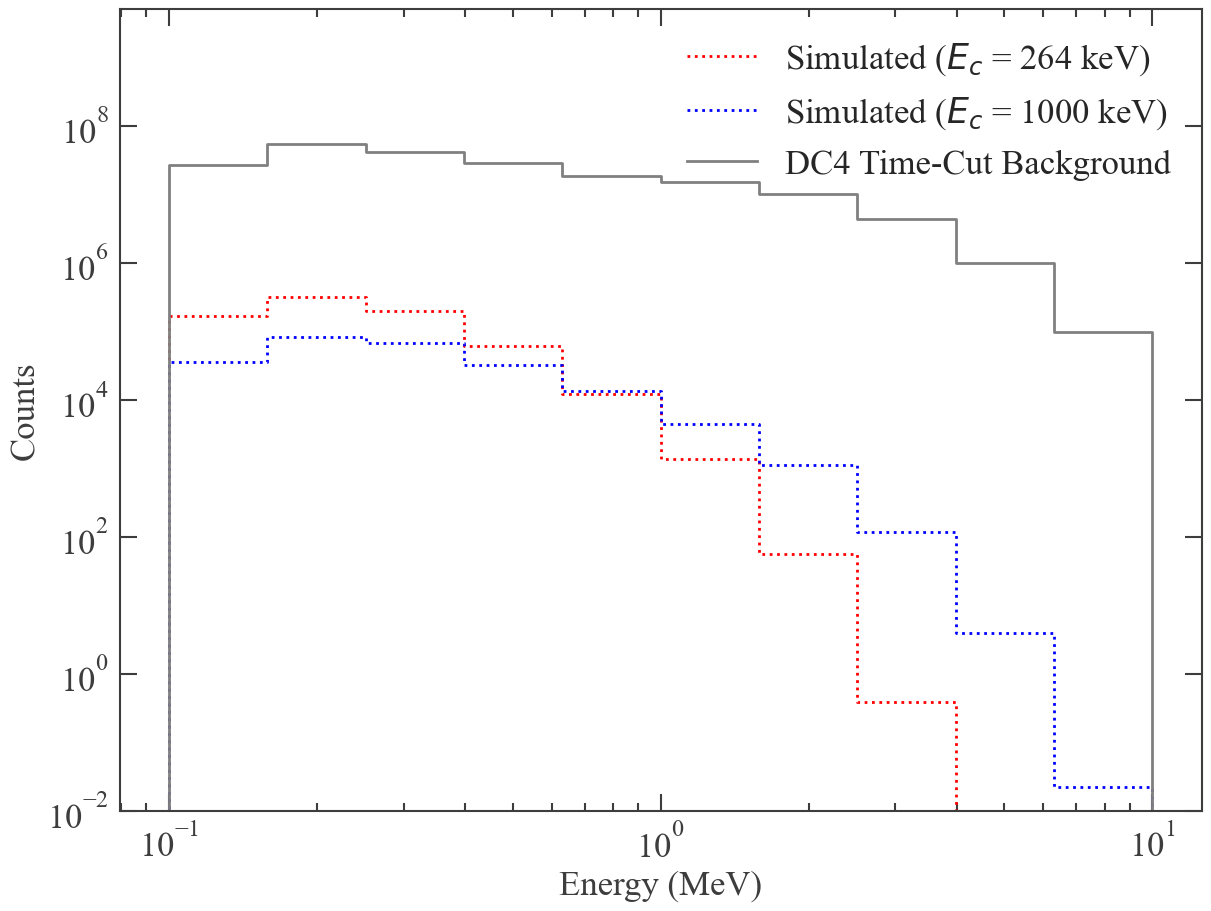

In [9]:
FONT_SIZE = 25
plt.rcParams['agg.path.chunksize'] = 10000

plt.rcParams.update({'font.size': FONT_SIZE})
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams.update({
    'font.weight': '550',
    'axes.titleweight': '550',
    'axes.labelweight': '550'
})

fig, ax = plt.subplots(figsize=(12, 9), constrained_layout=True)

ax.xaxis.set_tick_params(which='major', size=12, width=1.5, direction='in', top='on', pad=8, labelsize=FONT_SIZE)
ax.xaxis.set_tick_params(which='minor', size=6, width=1.5, direction='in', top='on', pad=8)
ax.yaxis.set_tick_params(which='major', size=12, width=1.5, direction='in', right='on', pad=8, labelsize=FONT_SIZE)
ax.yaxis.set_tick_params(which='minor', size=6, width=1.5, direction='in', right='on', pad=8)

ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)

draw_energy_hist_mev(NGC4151_ec200, ax, label="Simulated ($E_c$ = 264 keV)", color="red", linestyle="dotted")
draw_energy_hist_mev(NGC4151_ec1000, ax, label="Simulated ($E_c$ = 1000 keV)", color="blue", linestyle="dotted")
draw_energy_hist_mev(bkg, ax, label="DC4 Time-Cut Background", color="grey")
# draw_energy_hist_mev(full_bkg, ax, label="DC4 Full Background", color="black", linestyle="dashdot")
# draw_energy_hist_mev(NGC4151_ec200_bkg, ax, label="NGC 4151 Model ($E_c$ = 264 keV) + Background", linestyle='dashdot', color="red")
# draw_energy_hist_mev(NGC4151_ec1000_bkg, ax, label="NGC 4151 Model ($E_c$ = 1000 keV) + Background", linestyle='dashdot', color="blue")

ax.set_yscale("log")
ax.set_xscale("log")

ax.set_ylabel("Counts", fontsize=FONT_SIZE)
ax.set_ylim(1e-2, 5e9)

# ax.xaxis.set_major_locator(mticker.FixedLocator([0.2, 1, 5]))
# ax.xaxis.set_major_formatter(
#     mticker.FixedFormatter(["0.2", "1.0", "5.0"])
# )

ax.set_xlabel("Energy (MeV)", fontsize=FONT_SIZE)
ax.legend(fontsize=FONT_SIZE, loc='upper right', frameon=False)


## Perform spectral fit


Set background parameter, which is used to fit the amplitude of the background, and instantiate the COSI 3ML plugin


In [10]:
from agn_cosi_fit_utils import COSIPlugin, EnergyRangeCOSIPlugin, make_cosi_background_parameter

# Finite support for cells that are empty in the background histogram.
# This value is added to every cell before the background template is normalized.
# Use finite background support to avoid machine-tiny TS inflation.
BACKGROUND_PSEUDOCOUNT = 1e-12
bkg_par = Parameter("background_cosi",                                         # background parameter
                     1,                                                        # initial value of parameter
                     min_value=0,                                              # minimum value of parameter
                     max_value=5,                                              # maximum value of parameter
                     delta=0.05,                                               # initial step used by fitting engine
                     desc="Background parameter for cosi")

bkg_par_ec1000 = Parameter("background_cosi_ec1000",                           # background parameter
                     1,                                                        # initial value of parameter
                     min_value=0,                                              # minimum value of parameter
                     max_value=5,                                              # maximum value of parameter
                     delta=0.05,                                               # initial step used by fitting engine
                     desc="Background parameter for cosi")

cosi = COSIPlugin("cosi",                                                        # COSI 3ML plugin
                 dr = dr,                                                      # detector response
                 data = NGC4151_ec200_bkg.project('Em', 'Phi', 'PsiChi'),   # data (source+background)
                 bkg = bkg.project('Em', 'Phi', 'PsiChi'),         # background model 
                 sc_orientation = sc_orientation,                              # spacecraft orientation
                 nuisance_param = bkg_par,                                     # background parameter
                 background_pseudocount = BACKGROUND_PSEUDOCOUNT,              # regularize empty background cells
                 earth_occ = True)                                             # Option to account for Earth occultation

cosi_ec1000 = COSIPlugin("cosi",                                                        # COSI 3ML plugin
                 dr = dr,                                                      # detector response
                 data = NGC4151_ec1000_bkg.project('Em', 'Phi', 'PsiChi'),   # data (source+background)
                 bkg = bkg.project('Em', 'Phi', 'PsiChi'),         # background model 
                 sc_orientation = sc_orientation,                              # spacecraft orientation
                 nuisance_param = bkg_par_ec1000,                                     # background parameter
                 background_pseudocount = BACKGROUND_PSEUDOCOUNT,              # regularize empty background cells
                 earth_occ = True)                                             # Option to account for Earth occultation


### Powerlaw with energy cutoff fit


In [11]:
l=155.07
b=75.06

# Give it some harsher initial guesses
K = 1e-5 / u.cm / u.cm / u.s / u.keV
piv = 200. * u.keV
xc = 100. * u.keV
index = -1.75

spectrum_cpl = Cutoff_powerlaw()

spectrum_cpl.K.value = K.value
spectrum_cpl.piv.value = piv.value
spectrum_cpl.xc.value = xc.value
spectrum_cpl.index.value = index
# spectrum_cpl.index.fix = True

# Harsher Parameters
spectrum_cpl.K.min_value = 1e-8
spectrum_cpl.K.max_value = 1e-2
spectrum_cpl.xc.min_value = 100 # keep these relatively the same
spectrum_cpl.xc.max_value = 10000 # change to 1000
spectrum_cpl.index.min_value = -3 # change to -3.5 to sample lower, larger values (-5, 5)
spectrum_cpl.index.max_value = 1

# spectrum_cpl.K.delta = 0.05
# spectrum_cpl.xc.delta = 10
# spectrum_cpl.index.delta = 0.15

spectrum_cpl.K.unit = K.unit
spectrum_cpl.piv.unit = piv.unit
spectrum_cpl.xc.unit = xc.unit

source1 = PointSource("source1",                     # Name of source (arbitrary, but needs to be unique)
                     l = l,                        # Longitude (deg)
                     b = b,                        # Latitude (deg)
                     spectral_shape = spectrum_cpl)    # Spectral model


In [12]:
l=155.07
b=75.06

# Give it some harsher initial guesses
K = 1e-5 / u.cm / u.cm / u.s / u.keV
piv = 200. * u.keV
xc = 1000. * u.keV
index = -1.75

spectrum_cpl_ec1000 = Cutoff_powerlaw()

spectrum_cpl_ec1000.K.value = K.value
spectrum_cpl_ec1000.piv.value = piv.value
spectrum_cpl_ec1000.xc.value = xc.value
spectrum_cpl_ec1000.index.value = index
# spectrum_cpl_ec1000.index.fix = True

# Harsher Parameters
spectrum_cpl_ec1000.K.min_value = 1e-8
spectrum_cpl_ec1000.K.max_value = 1e-2
spectrum_cpl_ec1000.xc.min_value = 100 # keep these relatively the same
spectrum_cpl_ec1000.xc.max_value = 10000 # change to 1000
# spectrum_cpl_ec1000.index.min_value = -3 # change to -3.5 to sample lower, larger values (-5, 5)
# spectrum_cpl_ec1000.index.max_value = 1

# spectrum_cpl_ec1000.K.delta = 0.05
# spectrum_cpl_ec1000.xc.delta = 10
# spectrum_cpl_ec1000.index.delta = 0.15

spectrum_cpl_ec1000.K.unit = K.unit
spectrum_cpl_ec1000.piv.unit = piv.unit
spectrum_cpl_ec1000.xc.unit = xc.unit

source2 = PointSource("source2",                     # Name of source (arbitrary, but needs to be unique)
                     l = l,                        # Longitude (deg)
                     b = b,                        # Latitude (deg)
                     spectral_shape = spectrum_cpl_ec1000)    # Spectral model


In [13]:
model = Model(source1)  # Model with single source. If we had multiple sources, we would do Model(source1, source2, ...)
model_ec1000 = Model(source2)  # Model with single source. If we had multiple sources, we would do Model(source1, source2, ...)

cosi.set_model(model)
cosi_ec1000.set_model(model_ec1000)


### Joint Fit


In [14]:
# bat_ec200.use_effective_area_correction(0.02, 1.8)
# plugins = DataList(bat_ec200, cosi)

# bat_ec1000.use_effective_area_correction(0.02, 1.8)
# plugins_ec1000 = DataList(bat_ec1000, cosi_ec1000)


### Only COSI Fit


In [15]:
## Only COSI fit
plugins = DataList(cosi)
plugins_ec1000 = DataList(cosi_ec1000)


### Bright and Dim Fit


In [16]:
like = JointLikelihood(model, plugins, verbose = False)
like_ec1000 = JointLikelihood(model_ec1000, plugins_ec1000, verbose = False)

result = like.fit()
result_ec1000 = like_ec1000.fit()


15:47:37 INFO      set the minimizer to minuit                                             ]8;id=495326;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=283547;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

         INFO      set the minimizer to minuit                                             ]8;id=832173;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=346110;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

Best fit values:

,result,unit
parameter,,
source1.spectrum.main.Cutoff_powerlaw.K,(1.73 -0.23 +0.27) x 10^-5,1 / (keV s cm2)
source1.spectrum.main.Cutoff_powerlaw.index,-1.73 +/- 0.17,
source1.spectrum.main.Cutoff_powerlaw.xc,(2.7 +/- 0.5) x 10^2,keV
background_cosi,(2.55708 +/- 0.00026) x 10,Hz


Correlation matrix:

...

1.00,0.41,-0.69,-0.33
0.41,1.00,-0.83,0.08
-0.69,-0.83,1.00,-0.15
-0.33,0.08,-0.15,1.00


Values of -log(likelihood) at the minimum:

,-log(likelihood)
cosi,-1314456781.571405
total,-1314456781.571405


Values of statistical measures:

,statistical measures
AIC,-2628913555.1426363
BIC,-2628913513.752521


In [17]:
results = like.results
results_ec1000 = like_ec1000.results
results_sed = results
results_sed_ec1000 = results_ec1000
data_sed_hist = cosi._data.copy()
bkg_sed_hist = cosi._raw_bkg_hist.copy()
data_sed_ec1000_hist = cosi_ec1000._data.copy()
bkg_sed_ec1000_hist = cosi_ec1000._raw_bkg_hist.copy()

# print(results.display())

parameters = {par.name:results.get_variates(par.path)
              for par in results.optimized_model["source1"].parameters.values()
              if par.free}
parameters_ec1000 = {par.name:results_ec1000.get_variates(par.path)
              for par in results_ec1000.optimized_model["source2"].parameters.values()
              if par.free}

results_err = results.propagate(results.optimized_model["source1"].spectrum.main.shape.evaluate_at, **parameters)
results_err_ec1000 = results_ec1000.propagate(results_ec1000.optimized_model["source2"].spectrum.main.shape.evaluate_at, **parameters_ec1000)

# print(results.optimized_model["source"])


## Simultaneous COSI BinnedSED

Each true-energy bin uses the complete spectral shape from its fitted global model. All response-bin normalizations are fitted together to the saved representative realization with one Poisson likelihood. The COSI background rate is fixed to the global fit; per-bin TS and limits profile the other bin normalizations.


In [18]:
# The simultaneous BinnedSED fit is implemented in agn_binned_sed_fit_utils.py.
from agn_binned_sed_fit_utils import fit_global_binned_sed


In [19]:
from agn_binned_sed_fit_utils import fit_global_binned_sed

def include_finite_upper_limits(sed_df):
    """Show TS=0 bins when the joint fit supplies a finite 95% limit."""
    result = sed_df.copy()
    upper_limit = result['sed_ul95_erg_cm2_s'].to_numpy(dtype=float)
    valid_limit = np.isfinite(upper_limit) & (upper_limit > 0)
    omitted = result['plot_role'].eq('omitted').to_numpy()
    result.loc[omitted & valid_limit, 'plot_role'] = 'upper_limit'
    result.loc[result['plot_role'].eq('upper_limit').to_numpy() & ~valid_limit, 'plot_role'] = 'omitted'
    result['classification_rule'] = (
        'representative seed: TS<4 or one-sided fit -> upper limit when finite; '
        'omit only bins without a finite positive upper limit'
    )
    return result

thermal_cosi_sed_df = fit_global_binned_sed(
    global_results=results_sed, global_plugin=cosi,
    source_name='source1', dr_path=dr,
    sc_orientation=sc_orientation, longitude_deg=l, latitude_deg=b,
    calculate_upper3sigma=True, bayesian_ul_ts_threshold=1.0,
    calculate_asimov_sensitivity=True,
    background_pseudocount=BACKGROUND_PSEUDOCOUNT, label='bright_24m',
)
thermal_cosi_sed_df = include_finite_upper_limits(thermal_cosi_sed_df)
display(thermal_cosi_sed_df[["bin_index", "e_min_keV", "e_max_keV", "ts_value", "sed_ul95_erg_cm2_s", "plot_role"]])


,bin_index,e_min_keV,e_max_keV,ts_value,sed_ul95_erg_cm2_s,plot_role
0,1,100.000,158.489,1162.948544,6.597497e-10,detection
1,2,158.489,251.189,2558.413544,5.374312e-10,detection
2,3,251.189,398.107,1668.263500,4.168917e-10,detection
3,4,398.107,630.957,346.967867,2.459636e-10,detection
4,5,630.957,1000.000,16.723820,1.000608e-10,detection
5,6,1000.000,1584.890,0.647676,6.420909e-11,upper_limit
6,7,1584.890,2511.890,0.000000,2.722553e-11,upper_limit
7,8,2511.890,3981.070,0.000000,1.793142e-11,upper_limit
8,9,3981.070,6309.570,0.000000,3.875811e-12,upper_limit
9,10,6309.570,10000.000,0.000000,5.082758e-13,upper_limit


In [20]:
from agn_binned_sed_fit_utils import fit_global_binned_sed

thermal_cosi_sed_df_ec1000 = fit_global_binned_sed(
    global_results=results_sed_ec1000, global_plugin=cosi_ec1000,
    source_name='source2', dr_path=dr,
    sc_orientation=sc_orientation, longitude_deg=l, latitude_deg=b,
    calculate_upper3sigma=True, bayesian_ul_ts_threshold=1.0,
    calculate_asimov_sensitivity=True,
    background_pseudocount=BACKGROUND_PSEUDOCOUNT, label='dim_24m',
)
thermal_cosi_sed_df_ec1000 = include_finite_upper_limits(thermal_cosi_sed_df_ec1000)
display(thermal_cosi_sed_df_ec1000[["bin_index", "e_min_keV", "e_max_keV", "ts_value", "sed_ul95_erg_cm2_s", "plot_role"]])


,bin_index,e_min_keV,e_max_keV,ts_value,sed_ul95_erg_cm2_s,plot_role
0,1,100.000,158.489,75.013716,1.738795e-10,detection
1,2,158.489,251.189,172.597982,1.490235e-10,detection
2,3,251.189,398.107,154.906796,1.389441e-10,detection
3,4,398.107,630.957,82.009798,1.351611e-10,detection
4,5,630.957,1000.000,28.670786,1.311729e-10,detection
5,6,1000.000,1584.890,4.545281,1.180174e-10,detection
6,7,1584.890,2511.890,8.361435,1.473989e-10,detection
7,8,2511.890,3981.070,0.000000,4.192064e-11,upper_limit
8,9,3981.070,6309.570,0.000000,2.322216e-11,upper_limit
9,10,6309.570,10000.000,0.000000,1.467795e-11,upper_limit


In [21]:
FONT_SIZE = 25

plt.rcParams["agg.path.chunksize"] = 10000
plt.rcParams.update({"font.size": FONT_SIZE})
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["axes.linewidth"] = 1.5
plt.rcParams.update(
    {
        "font.weight": "550",
        "axes.titleweight": "550",
        "axes.labelweight": "550",
    }
)

def _make_xerr(df):
    return KEV_TO_MEV * np.vstack(
        [
            df["e_ref_keV"] - df["e_min_keV"],
            df["e_max_keV"] - df["e_ref_keV"],
        ]
    )

def _split_sed_detections(df):
    roles = df['plot_role'].astype(str)
    return (
        df.loc[roles == 'detection'].copy(),
        df.loc[roles == 'upper_limit'].copy(),
    )

def _style_sed_axis(ax):
    ax.xaxis.set_tick_params(which='major', size=12, width=1.5, direction='in', top='on', pad=8, labelsize=FONT_SIZE)
    ax.xaxis.set_tick_params(which='minor', size=6, width=1.5, direction='in', top='on', pad=8)
    ax.yaxis.set_tick_params(which='major', size=12, width=1.5, direction='in', right='on', pad=8, labelsize=FONT_SIZE)
    ax.yaxis.set_tick_params(which='minor', size=6, width=1.5, direction='in', right='on', pad=8)

    ax.spines['right'].set_visible(True)
    ax.spines['top'].set_visible(True)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim((85) * KEV_TO_MEV, (12000) * KEV_TO_MEV)
    ax.set_ylim(1e-2 * SED_KEV_TO_ERG, 1 * SED_KEV_TO_ERG)

    # ax.xaxis.set_major_locator(mticker.FixedLocator([0.1, 5, 10]))
    # ax.xaxis.set_major_formatter(mticker.FixedFormatter(["0.1", "5", "10"]))

    ax.set_xlabel('Energy (MeV)', fontsize=FONT_SIZE)
    ax.set_ylabel(r'Energy Flux (erg cm$^{-2}$ s$^{-1}$)', fontsize=FONT_SIZE)


## BinnedSED shape and background comparison

All four fits below use each state's same saved representative data, response bins, background template, and 95% profile-likelihood upper-limit rule. The **global** shape is the best-fit cutoff power law from the corresponding full-spectrum fit. The **default** shape is `BinnedSED.from_response` with no `spectral_shape` argument, which uses a fixed power law of index −2 within every true-energy bin. The background normalization is either held at its global-fit value or fitted jointly with all SED-bin normalizations. In both cases, every bin's TS and interval profile all other free parameters. Finite TS = 0 upper limits are retained. The tables and comparison plot are displayed only; this notebook saves no result files. The continuum curve in [Tomsick et al. (2023)](https://arxiv.org/html/2308.12362v1) is a 3σ point-source detection threshold for two years of all-sky survey time, while these points are 95% profile-likelihood bounds for one realization. The plotted bound also depends on the spectral shape assumed inside each broad response bin.

The four comparison panels also show each state’s injected cutoff-power-law spectrum as a dotted gray curve.

The dashed curves in each SED figure are **3σ per-bin Asimov detection thresholds** ([Cowan et al. 2011](https://arxiv.org/abs/1007.1727)) computed from the same 24-month response and background. Each true-energy bin is tested as the sole source component against background only. The calculation uses only detector cells with nonzero raw DC4 background support, so the pseudocount does not create artificial background-free sensitivity. All curves use the global-fit background as their expected background; the free-background panels profile its amplitude under the null hypothesis. The calculation uses expected counts, while the fitted spectral shape and background rate come from the selected realization. **The upper-limit fit uses all detector cells after adding a $10^{-12}$ background pseudocount, whereas this Asimov calculation excludes cells whose raw DC4 background is zero. The upper limits and dashed curves therefore do not use identical likelihood support; limits can be overconfident if those raw zero cells reflect finite background statistics.** The diagnostic table at the end reports their ratios and the fraction of each source template in raw-background-supported cells. These are not the published COSI survey sensitivity curves. The earlier counts histogram has different units and is not overlaid with an energy-flux threshold.


In [22]:
import pandas as pd
from agn_binned_sed_fit_utils import fit_global_binned_sed

comparison_states = {
    'Bright': (results_sed, cosi, 'source1', thermal_cosi_sed_df),
    'Dim': (results_sed_ec1000, cosi_ec1000, 'source2', thermal_cosi_sed_df_ec1000),
}
sed_comparisons = {}
comparison_tables = {}

for state, (global_result, global_plugin, source_name, existing_fixed_sed) in comparison_states.items():
    cases = {('global', 'fixed'): include_finite_upper_limits(existing_fixed_sed)}
    for shape_name, background_mode in (
        ('default E^-2', 'fixed'),
        ('global', 'free'),
        ('default E^-2', 'free'),
    ):
        sed = fit_global_binned_sed(
            global_results=global_result,
            global_plugin=global_plugin,
            source_name=source_name,
            dr_path=dr,
            sc_orientation=sc_orientation,
            longitude_deg=l,
            latitude_deg=b,
            background_pseudocount=BACKGROUND_PSEUDOCOUNT,
            label=f'{state.lower()}_{"pl2" if shape_name.startswith("default") else "global"}_{background_mode}_{exposure_4151}m',
            use_default_powerlaw_shape=shape_name.startswith('default'),
            free_background=background_mode == 'free',
            calculate_upper3sigma=True, bayesian_ul_ts_threshold=1.0,
            calculate_asimov_sensitivity=True,
        )
        cases[(shape_name, background_mode)] = include_finite_upper_limits(sed)
    sed_comparisons[state] = cases

    baseline = cases[('global', 'fixed')]
    summary = pd.DataFrame({
        'bin': baseline['bin_index'],
        'energy_MeV': baseline['e_ref_keV'] * KEV_TO_MEV,
    })
    for (shape_name, background_mode), sed in cases.items():
        name = f'{shape_name} / {background_mode}'
        summary[f'{name}: TS'] = sed['ts_value'].to_numpy()
        summary[f'{name}: role'] = sed['plot_role'].to_numpy()
        summary[f'{name}: 95% bound (erg cm^-2 s^-1)'] = sed['sed_ul95_erg_cm2_s'].to_numpy()
    comparison_tables[state] = summary
    print(f'{state} state: fitted background rates (Hz)')
    for (shape_name, background_mode), sed in cases.items():
        print(f'  {shape_name}, {background_mode}: {sed["background_rate_hz"].iloc[0]:.6g}')
    display(summary)


Bright state: fitted background rates (Hz)
  global, fixed: 25.5708
  default E^-2, fixed: 25.5708
  global, free: 25.5708
  default E^-2, free: 25.5718


,bin,energy_MeV,global / fixed: TS,global / fixed: role,global / fixed: 95% bound (erg cm^-2 s^-1),default E^-2 / fixed: TS,default E^-2 / fixed: role,default E^-2 / fixed: 95% bound (erg cm^-2 s^-1),global / free: TS,global / free: role,global / free: 95% bound (erg cm^-2 s^-1),default E^-2 / free: TS,default E^-2 / free: role,default E^-2 / free: 95% bound (erg cm^-2 s^-1)
0,1,0.125892,1162.948544,detection,6.597497e-10,1162.948544,detection,6.594818e-10,1.062981e+03,detection,6.642774e-10,1053.601957,detection,6.598295e-10
1,2,0.199526,2558.413544,detection,5.374312e-10,2558.413544,detection,5.393290e-10,2.137603e+03,detection,5.417336e-10,2124.006015,detection,5.418229e-10
2,3,0.316228,1668.263500,detection,4.168917e-10,1668.263500,detection,4.220649e-10,1.447672e+03,detection,4.208443e-10,1398.463154,detection,4.275930e-10
3,4,0.501187,346.967867,detection,2.459636e-10,346.967867,detection,2.541128e-10,3.093379e+02,detection,2.467834e-10,309.698235,detection,2.558796e-10
4,5,0.794328,16.723820,detection,1.000608e-10,16.723820,detection,1.083691e-10,1.463814e+01,detection,1.041695e-10,12.020076,detection,1.095568e-10
5,6,1.258924,0.647676,upper_limit,6.420909e-11,0.647676,upper_limit,7.755439e-11,5.209743e-01,upper_limit,6.363393e-11,0.425546,upper_limit,7.495159e-11
6,7,1.995262,0.000000,upper_limit,2.722553e-11,0.000000,upper_limit,4.198347e-11,0.000000e+00,upper_limit,2.818421e-11,0.000000,upper_limit,4.167900e-11
7,8,3.162279,0.000000,upper_limit,1.793142e-11,0.000000,upper_limit,4.624907e-11,0.000000e+00,upper_limit,1.791810e-11,0.000000,upper_limit,4.564411e-11
8,9,5.011870,0.000000,upper_limit,3.875811e-12,0.000000,upper_limit,2.714113e-11,0.000000e+00,upper_limit,3.874100e-12,0.000000,upper_limit,3.066826e-11
9,10,7.943280,0.000000,upper_limit,5.082758e-13,0.000000,upper_limit,2.156781e-11,6.984919e-10,upper_limit,5.082074e-13,0.000000,upper_limit,2.153923e-11


Dim state: fitted background rates (Hz)
  global, fixed: 25.5711
  default E^-2, fixed: 25.5711
  global, free: 25.5711
  default E^-2, free: 25.5712


,bin,energy_MeV,global / fixed: TS,global / fixed: role,global / fixed: 95% bound (erg cm^-2 s^-1),default E^-2 / fixed: TS,default E^-2 / fixed: role,default E^-2 / fixed: 95% bound (erg cm^-2 s^-1),global / free: TS,global / free: role,global / free: 95% bound (erg cm^-2 s^-1),default E^-2 / free: TS,default E^-2 / free: role,default E^-2 / free: 95% bound (erg cm^-2 s^-1)
0,1,0.125892,75.013716,detection,1.738795e-10,75.013716,detection,1.737316e-10,69.317793,detection,1.769935e-10,68.187962,detection,1.793028e-10
1,2,0.199526,172.597982,detection,1.490235e-10,172.597982,detection,1.489835e-10,144.598391,detection,1.505065e-10,145.496383,detection,1.515688e-10
2,3,0.316228,154.906796,detection,1.389441e-10,154.906796,detection,1.390542e-10,131.331254,detection,1.403534e-10,133.430036,detection,1.427517e-10
3,4,0.501187,82.009798,detection,1.351611e-10,82.009798,detection,1.355420e-10,76.218972,detection,1.362969e-10,74.903586,detection,1.382502e-10
4,5,0.794328,28.670786,detection,1.311729e-10,28.670786,detection,1.320774e-10,26.464605,detection,1.337512e-10,26.129150,detection,1.374295e-10
5,6,1.258924,4.545281,detection,1.180174e-10,4.545282,detection,1.198505e-10,4.692768,detection,1.219174e-10,4.314771,detection,1.284712e-10
6,7,1.995262,8.361435,detection,1.473989e-10,8.361435,detection,1.525155e-10,6.317206,detection,1.583135e-10,6.441851,detection,1.871559e-10
7,8,3.162279,0.000000,upper_limit,4.192064e-11,0.000000,upper_limit,4.523926e-11,0.000000,upper_limit,6.306913e-11,0.000000,upper_limit,6.739979e-11
8,9,5.011870,0.000000,upper_limit,2.322216e-11,0.000000,upper_limit,2.756446e-11,0.000000,upper_limit,2.508678e-11,0.000000,upper_limit,3.310215e-11
9,10,7.943280,0.000000,upper_limit,1.467795e-11,0.000000,upper_limit,2.152869e-11,0.000000,upper_limit,1.600925e-11,0.000000,upper_limit,2.451989e-11


In [23]:
# For each non-detection, compare the plotted pivot bound with the same
# fitted bin normalization evaluated just inside that bin's lower edge.
# This exposes the large within-bin correction made by a steep cutoff shape.
diagnostic_rows = []
for state, (global_result, _, source_name, _) in comparison_states.items():
    global_shape = global_result.optimized_model[source_name].spectrum.main.shape
    for (shape_name, background_mode), sed in sed_comparisons[state].items():
        upper = sed.loc[sed['plot_role'].eq('upper_limit')]
        for _, point in upper.iterrows():
            e_min = float(point['e_min_keV'])
            e_ref = float(point['e_ref_keV'])
            if shape_name == 'global':
                shape_ratio = float(global_shape.evaluate_at(e_min)) / float(global_shape.evaluate_at(e_ref))
            else:
                shape_ratio = (e_min / e_ref) ** -2
            edge_factor = (e_min / e_ref) ** 2 * shape_ratio
            diagnostic_rows.append({
                'state': state,
                'shape': shape_name,
                'background': background_mode,
                'bin': int(point['bin_index']),
                'bin lower edge (MeV)': e_min * KEV_TO_MEV,
                'pivot (MeV)': e_ref * KEV_TO_MEV,
                'TS': float(point['ts_value']),
                '95% bound at pivot': float(point['sed_ul95_erg_cm2_s']),
                'same bound at lower edge': float(point['sed_ul95_erg_cm2_s']) * edge_factor,
                'lower-edge / pivot': edge_factor,
            })
upper_limit_diagnostics = pd.DataFrame(diagnostic_rows)
display(upper_limit_diagnostics)


,state,shape,background,bin,bin lower edge (MeV),pivot (MeV),TS,95% bound at pivot,same bound at lower edge,lower-edge / pivot
0,Bright,global,fixed,6,1.00000,1.258924,6.476760e-01,6.420909e-11,1.568199e-10,2.442332
1,Bright,global,fixed,7,1.58489,1.995262,0.000000e+00,2.722553e-11,1.163029e-10,4.271833
2,Bright,global,fixed,8,2.51189,3.162279,0.000000e+00,1.793142e-11,1.857974e-10,10.361556
3,Bright,global,fixed,9,3.98107,5.011870,0.000000e+00,3.875811e-12,1.635628e-10,42.200927
4,Bright,global,fixed,10,6.30957,7.943280,0.000000e+00,5.082758e-13,1.986292e-10,390.790263
5,Bright,default E^-2,fixed,6,1.00000,1.258924,6.476760e-01,7.755439e-11,7.755439e-11,1.000000
6,Bright,default E^-2,fixed,7,1.58489,1.995262,0.000000e+00,4.198347e-11,4.198347e-11,1.000000
7,Bright,default E^-2,fixed,8,2.51189,3.162279,0.000000e+00,4.624907e-11,4.624907e-11,1.000000
8,Bright,default E^-2,fixed,9,3.98107,5.011870,0.000000e+00,2.714113e-11,2.714113e-11,1.000000
9,Bright,default E^-2,fixed,10,6.30957,7.943280,0.000000e+00,2.156781e-11,2.156781e-11,1.000000


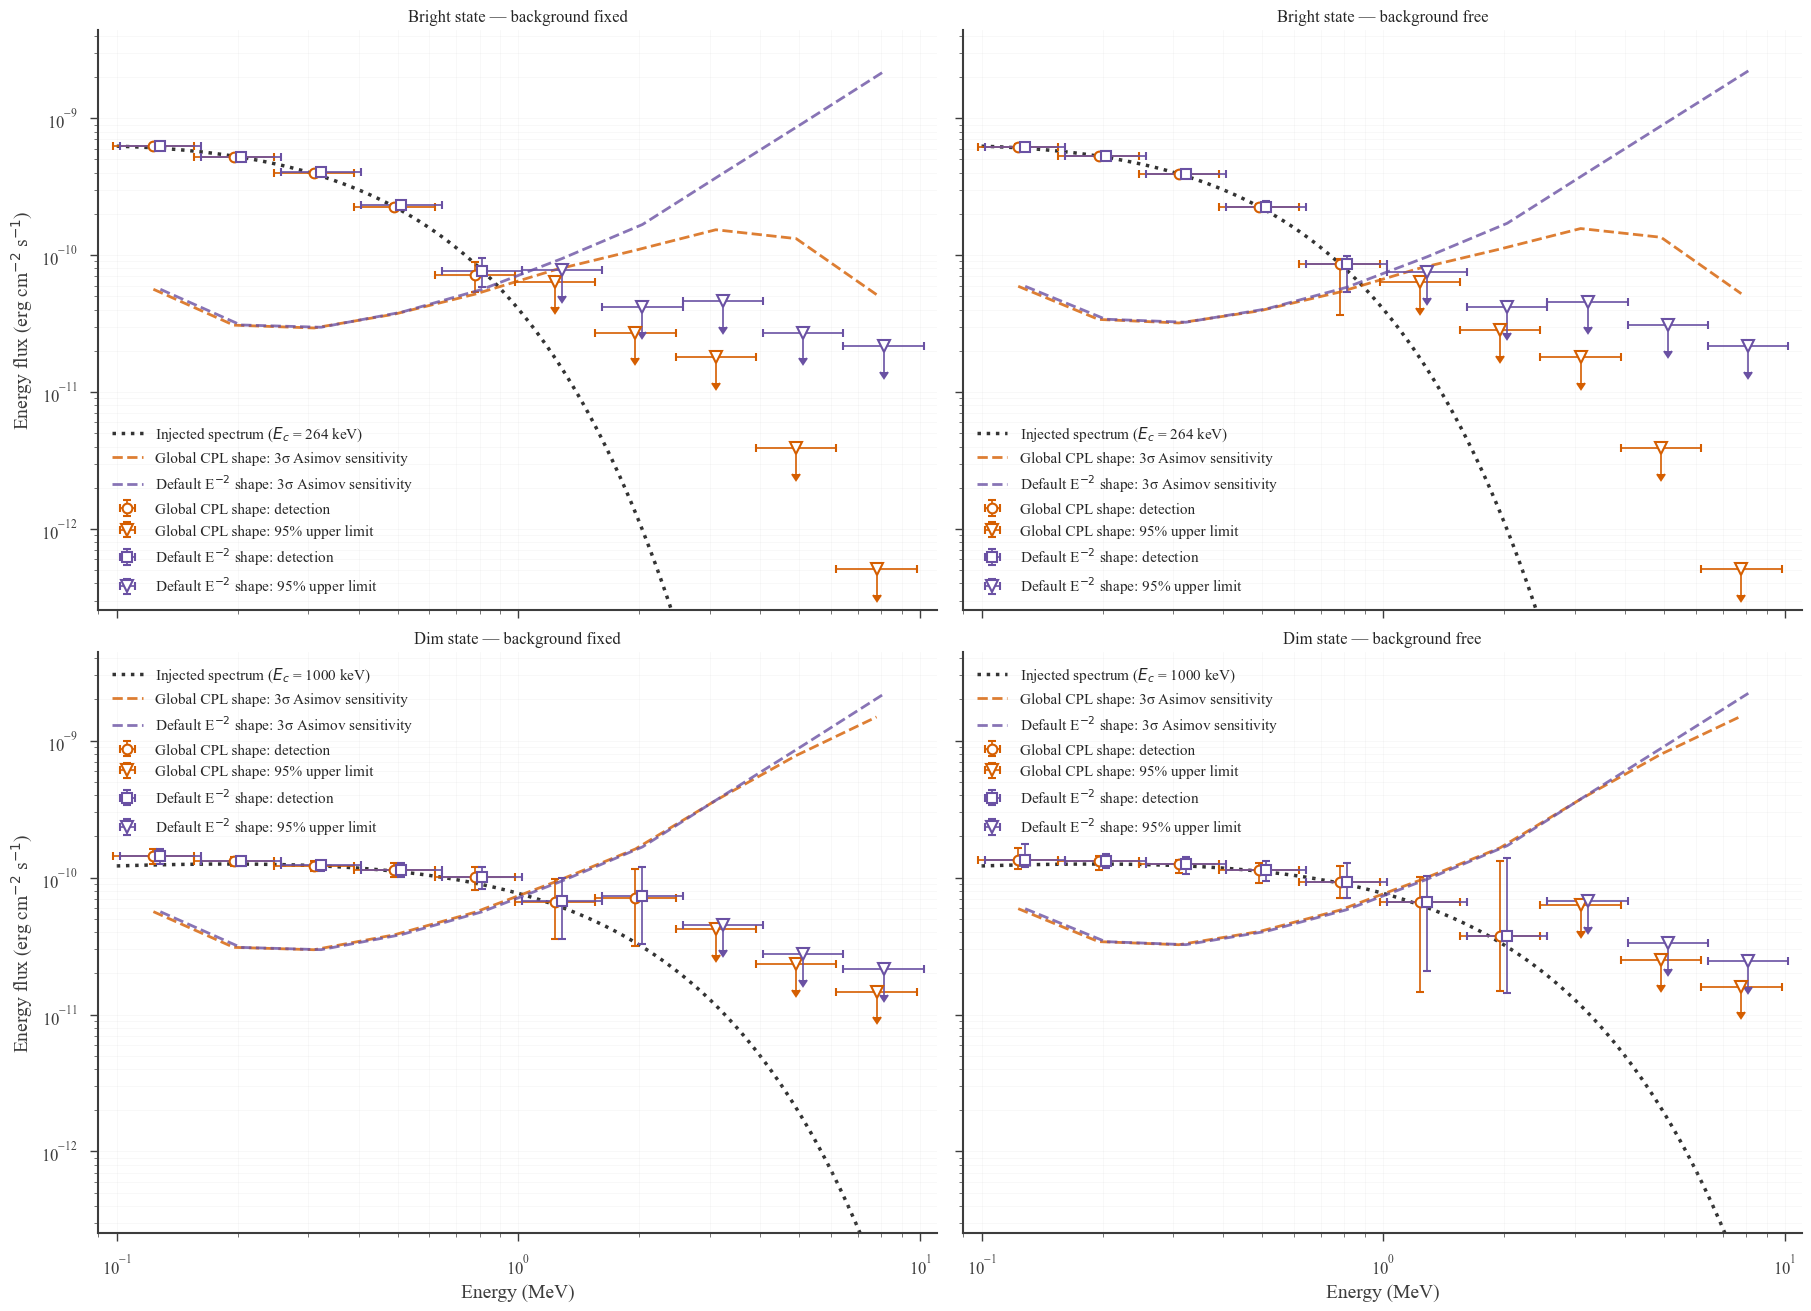

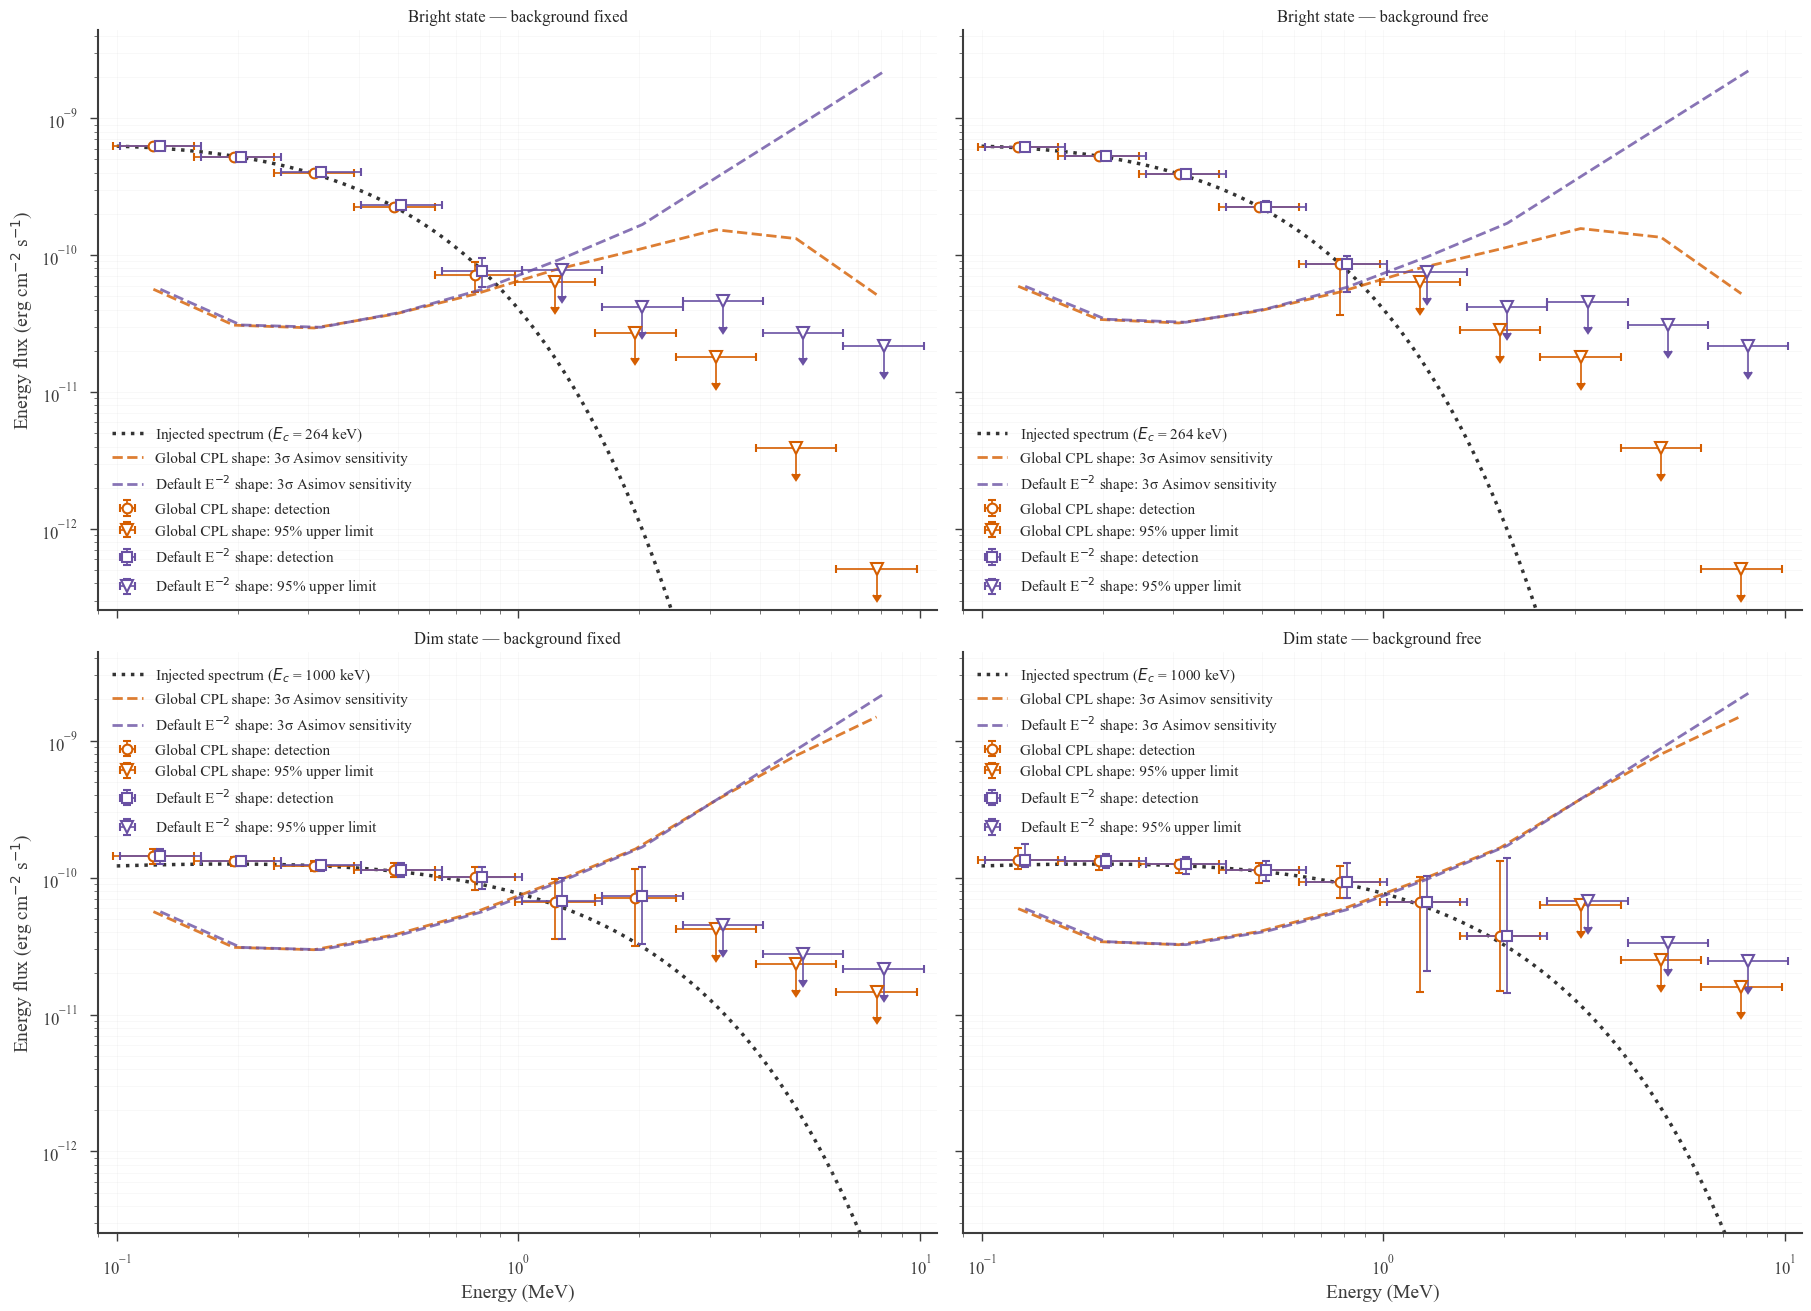

In [30]:
def _plot_asimov_sensitivity(ax, sed, *, color, shape_label, xshift):
    threshold = sed['sed_asimov_sensitivity3sigma_erg_cm2_s'].to_numpy(dtype=float)
    valid = np.isfinite(threshold) & (threshold > 0)
    if not np.any(valid):
        raise ValueError(f'No finite 3σ Asimov sensitivity for {shape_label}')
    ax.plot(sed.loc[valid, 'e_ref_keV'] * KEV_TO_MEV * xshift,
            threshold[valid], '--x', color=color, lw=2.0,
            markersize=5, alpha=0.8, zorder=2,
            label=f'{shape_label}: 3σ Asimov sensitivity')
    return threshold[valid]

def _plot_comparison_sed(ax, sed, *, color, marker, shape_label, xshift):
    detections, upper_limits = _split_sed_detections(sed)
    if not detections.empty:
        y = detections['sed_erg_cm2_s'].to_numpy(dtype=float)
        yerr = np.vstack([
            np.maximum(y - detections['sed_lo_erg_cm2_s'].to_numpy(dtype=float), 0),
            np.maximum(detections['sed_hi_erg_cm2_s'].to_numpy(dtype=float) - y, 0),
        ])
        ax.errorbar(
            detections['e_ref_keV'] * KEV_TO_MEV * xshift, y,
            xerr=_make_xerr(detections) * xshift, yerr=yerr,
            fmt=marker, color=color, markerfacecolor='white', markeredgewidth=1.5,
            elinewidth=1.2, capsize=3, markersize=7,
            label=f'{shape_label}: detection',
        )
    if not upper_limits.empty:
        y = upper_limits['sed_ul95_erg_cm2_s'].to_numpy(dtype=float)
        ax.errorbar(
            upper_limits['e_ref_keV'] * KEV_TO_MEV * xshift, y,
            xerr=_make_xerr(upper_limits) * xshift,
            yerr=np.maximum(0.35 * y, np.finfo(float).tiny), uplims=True,
            fmt='v', color=color, markerfacecolor='white', markeredgewidth=1.5,
            elinewidth=1.2, capsize=3, markersize=8,
            label=f'{shape_label}: 95% upper limit',
        )

injected_energy_keV = np.geomspace(100.0, 10000.0, 400)
injected_models = {
    'Bright': (spectrum_inj_ec200, 264),
    'Dim': (spectrum_inj_ec1000, 1000),
}
injected_sed = {}
for state, (model, cutoff_keV) in injected_models.items():
    photon_flux = np.array([float(model.evaluate_at(e)) for e in injected_energy_keV])
    injected_sed[state] = SED_KEV_TO_ERG * injected_energy_keV**2 * photon_flux

fig, axes = plt.subplots(2, 2, figsize=(18, 13), sharex=True, sharey=True, constrained_layout=True)
for row, state in enumerate(('Bright', 'Dim')):
    for col, background_mode in enumerate(('fixed', 'free')):
        ax = axes[row, col]
        ax.plot(
            injected_energy_keV * KEV_TO_MEV, injected_sed[state],
            color='0.2', linestyle=':', linewidth=2.5,
            label=f'Injected spectrum ($E_c$ = {injected_models[state][1]} keV)',
            zorder=1,
        )
        _plot_asimov_sensitivity(
            ax, sed_comparisons[state][('global', background_mode)],
            color='#D55E00', shape_label='Global CPL shape', xshift=0.98,
        )
        _plot_comparison_sed(
            ax, sed_comparisons[state][('global', background_mode)],
            color='#D55E00', marker='o', shape_label='Global CPL shape', xshift=0.98,
        )
        _plot_asimov_sensitivity(
            ax, sed_comparisons[state][('default E^-2', background_mode)],
            color='#6A51A3', shape_label='Default E$^{-2}$ shape', xshift=1.02,
        )
        _plot_comparison_sed(
            ax, sed_comparisons[state][('default E^-2', background_mode)],
            color='#6A51A3', marker='s', shape_label='Default E$^{-2}$ shape', xshift=1.02,
        )
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(0.09, 11)
        ax.set_title(f'{state} state — background {background_mode}')
        ax.grid(alpha=0.15, which='both')
        ax.legend(frameon=False, fontsize=11)
        if col == 0:
            ax.set_ylabel(r'Energy flux (erg cm$^{-2}$ s$^{-1}$)')
        if row == 1:
            ax.set_xlabel('Energy (MeV)')

# Scale to the fitted points and bounds so the cutoff tail does not flatten the panels.
plotted_sed_values = []
for cases in sed_comparisons.values():
    for sed in cases.values():
        detections, upper_limits = _split_sed_detections(sed)
        plotted_sed_values.extend(detections['sed_erg_cm2_s'].to_numpy(dtype=float))
        plotted_sed_values.extend(upper_limits['sed_ul95_erg_cm2_s'].to_numpy(dtype=float))
        plotted_sed_values.extend(sed['sed_asimov_sensitivity3sigma_erg_cm2_s'].to_numpy(dtype=float))
plotted_sed_values = np.asarray(plotted_sed_values, dtype=float)
plotted_sed_values = plotted_sed_values[np.isfinite(plotted_sed_values) & (plotted_sed_values > 0)]
if plotted_sed_values.size:
    injected_peak = max(np.nanmax(values) for values in injected_sed.values())
    axes[0, 0].set_ylim(plotted_sed_values.min() / 2, max(plotted_sed_values.max(), injected_peak) * 2)

display(fig)


## Three-sigma and Bayesian upper-limit comparison

The next plot compares the existing 95% profile-likelihood upper limits with 3σ profile limits (\(2\Delta\ln\mathcal{L}=9\)). The final plot compares 95% profile limits with 95% Bayesian limits in bins with **TS < 1**. For the Bayesian calculation, the bin normalization has a flat prior from zero to its allowed maximum, while all other fitted bin normalizations and the fitted background are held fixed. This follows the [Fermi Science Tools SED Bayesian option](https://github.com/fermi-lat/pyLikelihood/blob/master/python/SED.py), which freezes other parameters during the integration. [FermiPy’s standard SED method](https://fermipy.readthedocs.io/en/latest/advanced/sed.html) instead reports profile-likelihood limits. All figures and tables below are displayed without saving files. Neither type of limit is a 3σ detection-sensitivity curve.

Both comparison figures also display the same shape- and background-matched 3σ Asimov threshold curves as the first SED figure.


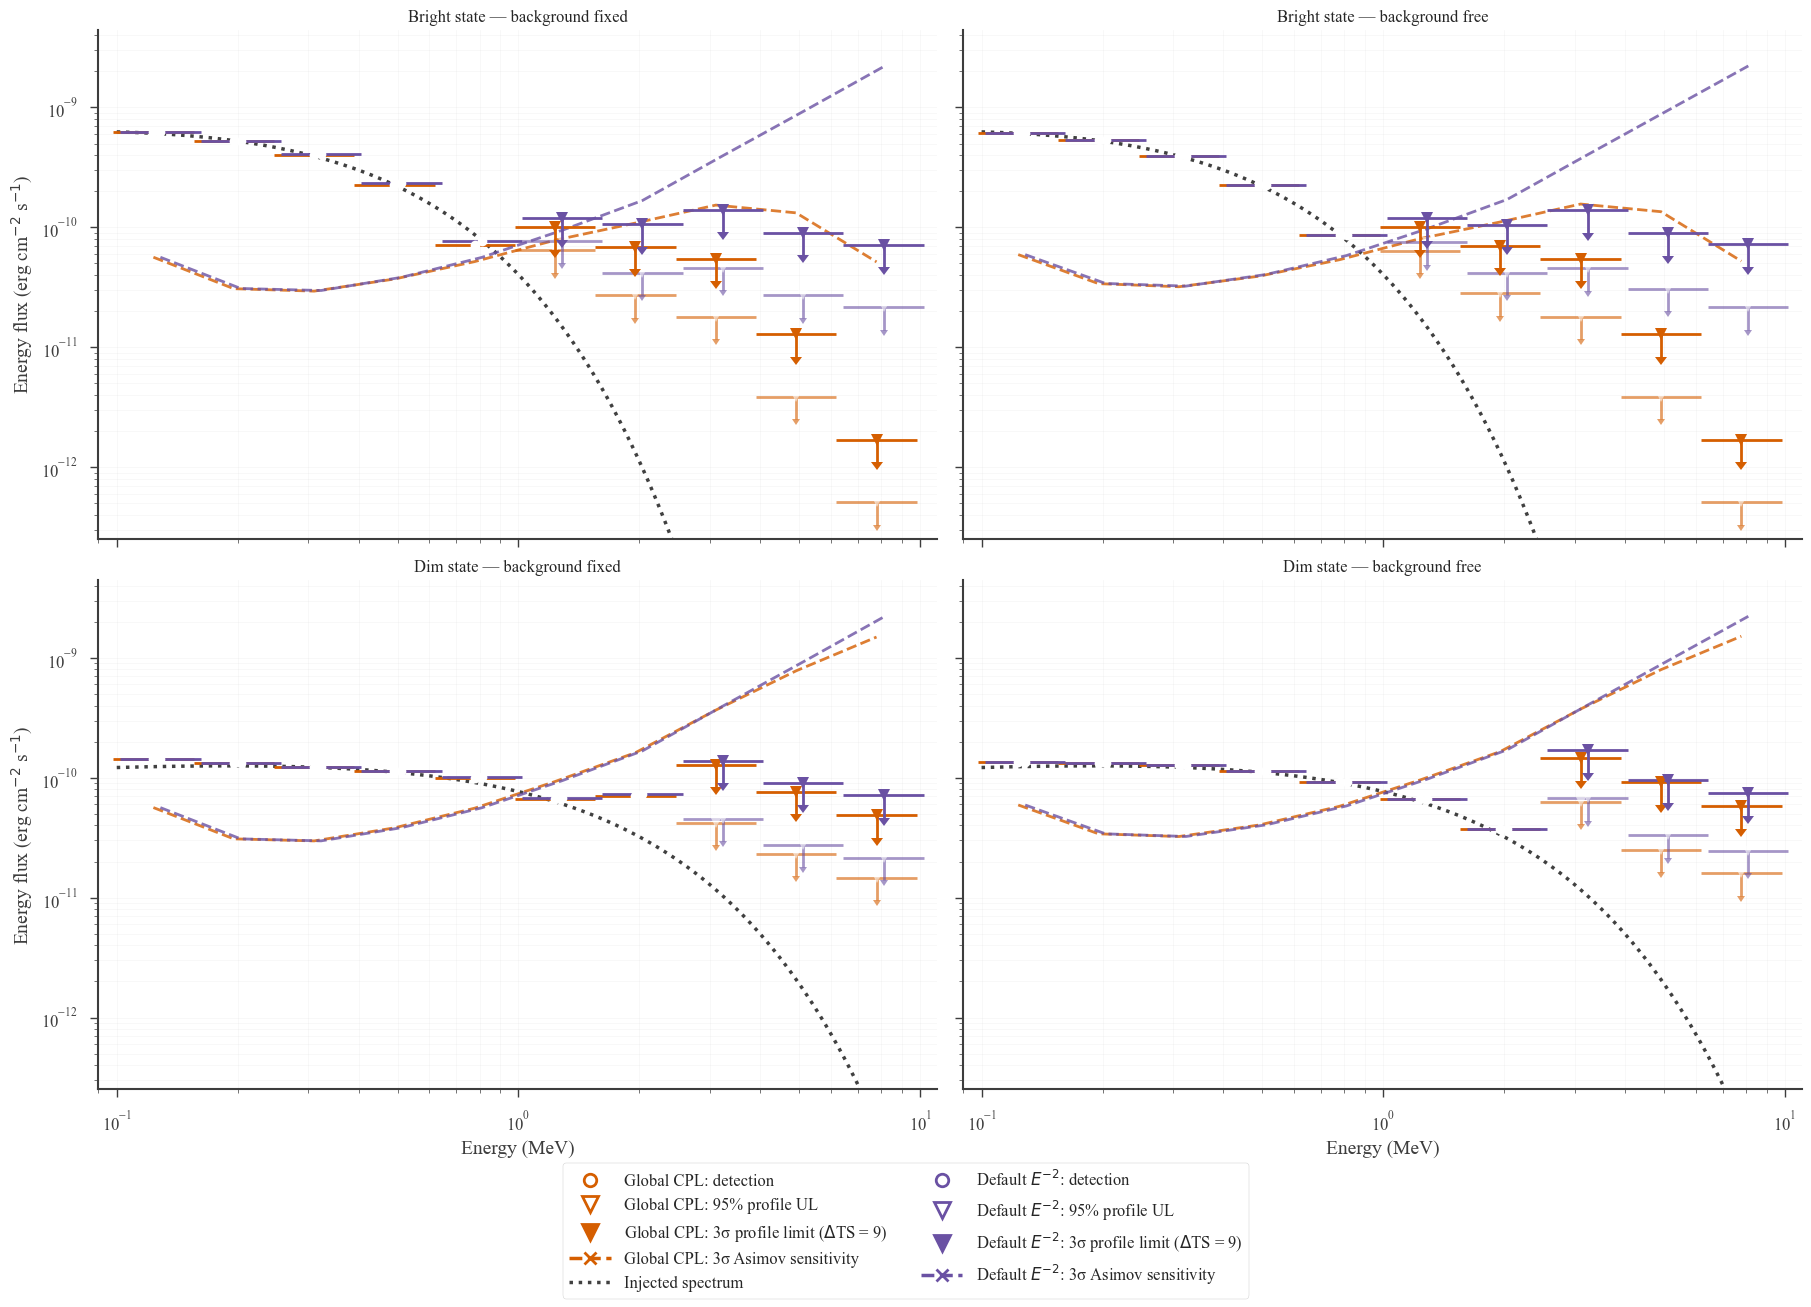

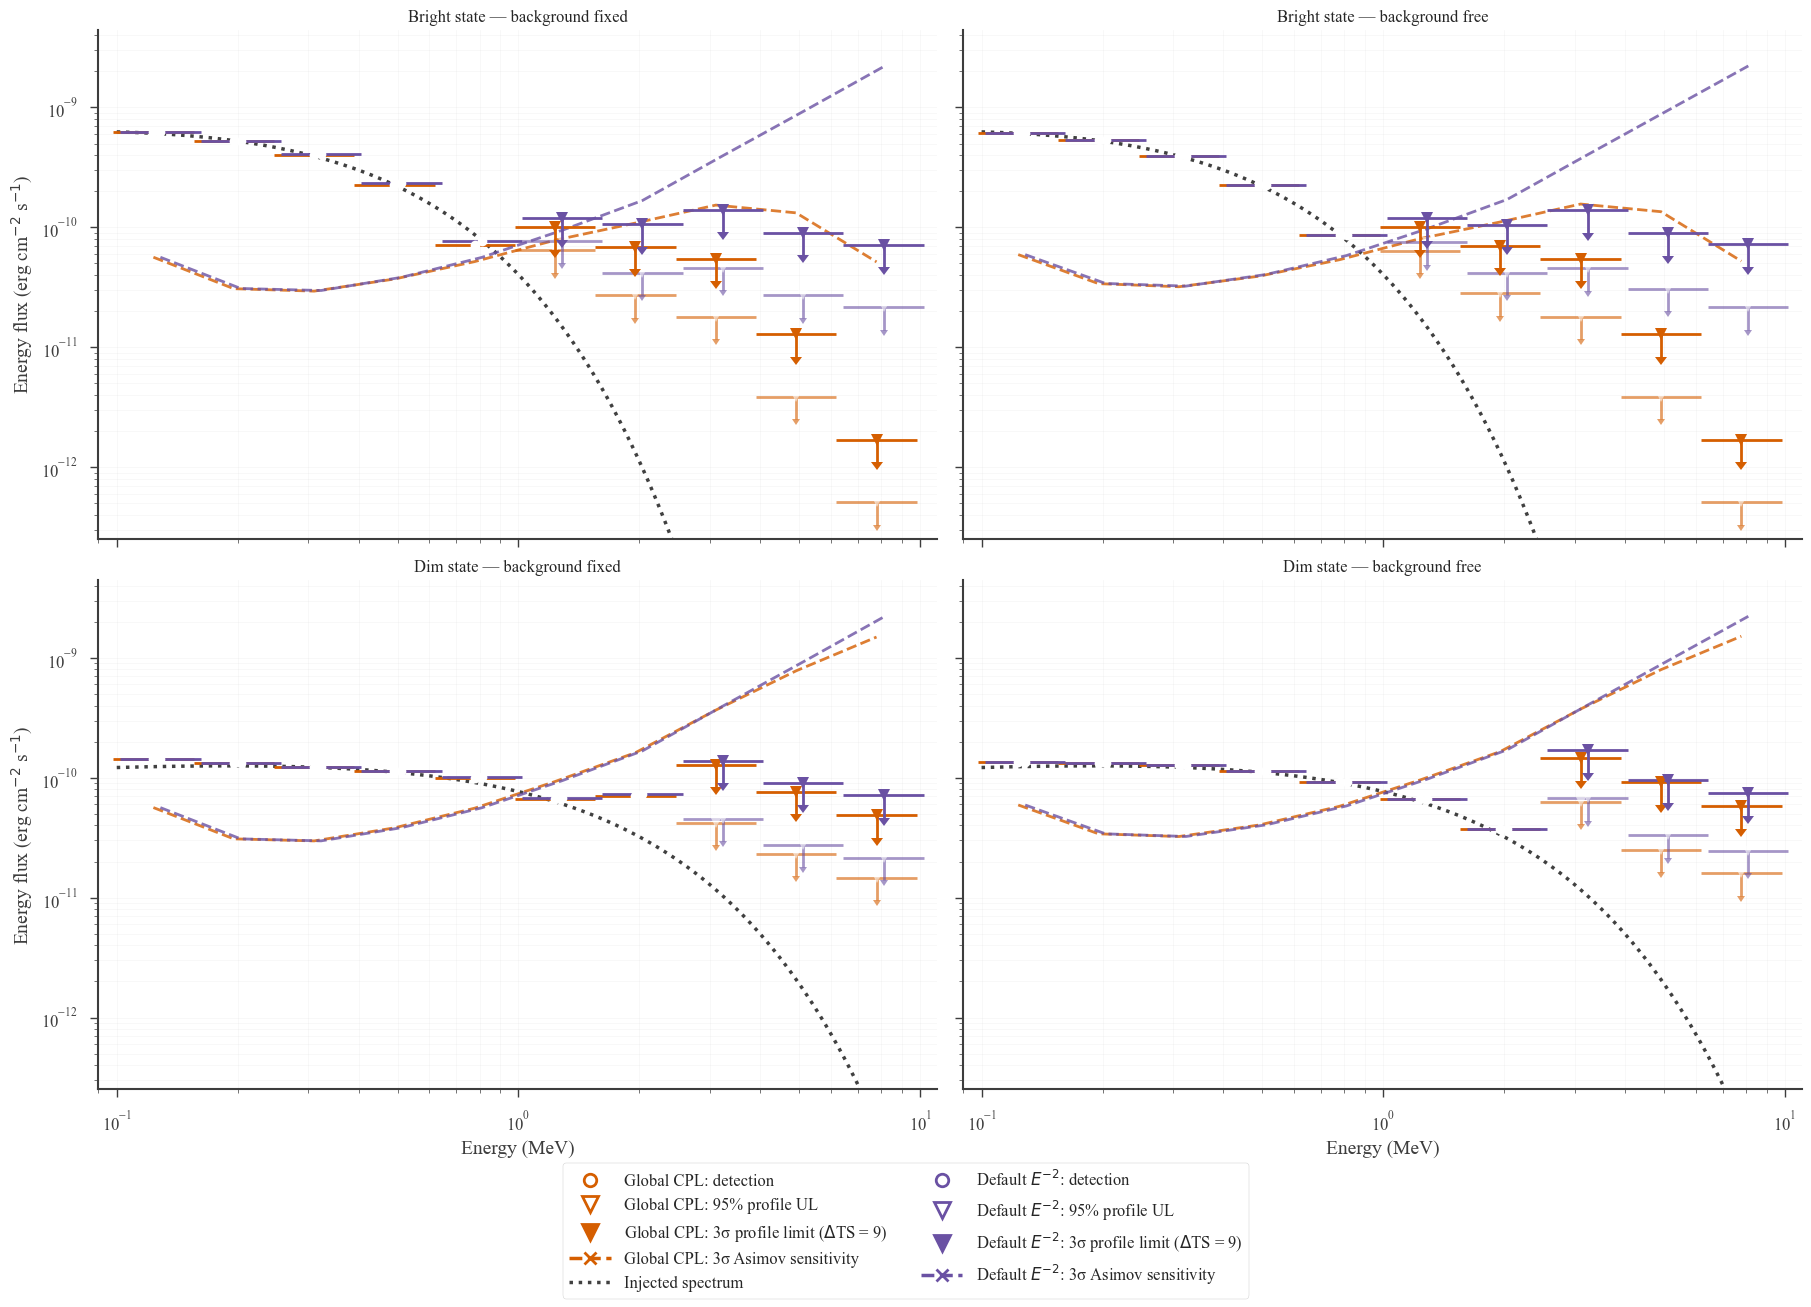

In [31]:
# Open triangles: 95% profile limits. Filled triangles: the requested limit.
from matplotlib.lines import Line2D
shape_colors = {'global': '#D55E00', 'default E^-2': '#6A51A3'}

def plot_limit_comparison(limit_column, method_label, *, ts_below_one=False):
    fig, axes = plt.subplots(2, 2, figsize=(18, 13), sharex=True, sharey=True,
                             constrained_layout=True)
    plotted = []
    for row, state in enumerate(('Bright', 'Dim')):
        for col, background_mode in enumerate(('fixed', 'free')):
            ax = axes[row, col]
            ax.plot(injected_energy_keV * KEV_TO_MEV, injected_sed[state],
                    color='0.25', ls=':', lw=2.5)
            for shape_name, xshift in (('global', 0.98), ('default E^-2', 1.02)):
                sed = sed_comparisons[state][(shape_name, background_mode)]
                plotted.extend(_plot_asimov_sensitivity(
                    ax, sed, color=shape_colors[shape_name],
                    shape_label=shape_name, xshift=xshift,
                ))
                if ts_below_one:
                    limits = sed.loc[sed['ts_value'] < 1.0]
                else:
                    detections, limits = _split_sed_detections(sed)
                    if not detections.empty:
                        y = detections['sed_erg_cm2_s'].to_numpy(dtype=float)
                        ax.errorbar(detections['e_ref_keV'] * KEV_TO_MEV * xshift, y,
                                    xerr=_make_xerr(detections) * xshift,
                                    fmt='o', color=shape_colors[shape_name],
                                    markerfacecolor='white', markersize=7, capsize=3)
                        plotted.extend(y)
                if limits.empty:
                    continue
                reference = limits['sed_ul95_erg_cm2_s'].to_numpy(dtype=float)
                proposed = limits[limit_column].to_numpy(dtype=float)
                if np.any(~np.isfinite(reference) | (reference <= 0)):
                    raise ValueError(f'{state}, {shape_name}, {background_mode}: invalid 95% profile limit')
                if np.any(~np.isfinite(proposed) | (proposed <= 0)):
                    raise ValueError(f'{state}, {shape_name}, {background_mode}: invalid {method_label} limit')
                x = limits['e_ref_keV'] * KEV_TO_MEV * xshift
                xerr = _make_xerr(limits) * xshift
                color = shape_colors[shape_name]
                ax.errorbar(x, reference, xerr=xerr, yerr=0.35 * reference,
                            uplims=True, fmt='v', color=color, markerfacecolor='white',
                            markersize=7, capsize=3, alpha=0.6, zorder=3)
                ax.errorbar(x, proposed, xerr=xerr, yerr=0.35 * proposed,
                            uplims=True, fmt='v', color=color, markerfacecolor=color,
                            markersize=9, capsize=4, zorder=4)
                plotted.extend(reference)
                plotted.extend(proposed)
            ax.set_xscale('log')
            ax.set_yscale('log')
            ax.set_xlim(0.09, 11)
            ax.set_title(f'{state} state — background {background_mode}' +
                         ('; TS < 1' if ts_below_one else ''))
            ax.grid(alpha=0.15, which='both')
            if col == 0:
                ax.set_ylabel(r'Energy flux (erg cm$^{-2}$ s$^{-1}$)')
            if row == 1:
                ax.set_xlabel('Energy (MeV)')
    plotted = np.asarray(plotted, dtype=float)
    plotted = plotted[np.isfinite(plotted) & (plotted > 0)]
    if plotted.size:
        injected_peak = max(np.nanmax(v) for v in injected_sed.values())
        axes[0, 0].set_ylim(plotted.min() / 2, max(plotted.max(), injected_peak) * 2)
    # Give each colored symbol its own label so no legend keys need combining.
    injected_handle = Line2D([], [], color='0.25', ls=':', lw=2.5,
                             label='Injected spectrum')
    handles = []
    for shape_name, shape_label in (
        ('global', 'Global CPL'), ('default E^-2', r'Default $E^{-2}$')
    ):
        color = shape_colors[shape_name]
        if not ts_below_one:
            handles.append(Line2D([], [], color=color, marker='o', ls='None',
                                  markersize=9, markerfacecolor='white',
                                  markeredgecolor=color, markeredgewidth=2,
                                  label=f'{shape_label}: detection'))
        handles.extend([
            Line2D([], [], color=color, marker='v', ls='None', markersize=11,
                   markerfacecolor='white', markeredgecolor=color,
                   markeredgewidth=2, label=f'{shape_label}: 95% profile UL'),
            Line2D([], [], color=color, marker='v', ls='None', markersize=11,
                   markerfacecolor=color, markeredgecolor=color,
                   markeredgewidth=2, label=f'{shape_label}: {method_label}'),
            Line2D([], [], color=color, marker='x', ls='--', lw=2.5,
                   markersize=8, markeredgewidth=2,
                   label=f'{shape_label}: 3σ Asimov sensitivity'),
        ])
        if shape_name == 'global':
            handles.append(injected_handle)
    fig.legend(handles=handles, loc='outside lower center', ncol=2,
               frameon=True, facecolor='white', edgecolor='0.75',
               framealpha=0.98, fontsize=12, handlelength=2.5)
    return fig

fig_3sigma = plot_limit_comparison('sed_ul3sigma_erg_cm2_s',
                                    r'3σ profile limit ($\Delta$TS = 9)')
display(fig_3sigma)


,state,shape,background,bin,energy_MeV,TS,profile_95,bayesian_95,bayes_to_profile
0,Bright,global,fixed,6,1.258924,6.476760e-01,6.420909e-11,6.693005e-11,1.042377
1,Bright,global,fixed,7,1.995262,0.000000e+00,2.722553e-11,4.486975e-11,1.648076
2,Bright,global,fixed,8,3.162279,0.000000e+00,1.793142e-11,3.596943e-11,2.005944
3,Bright,global,fixed,9,5.011870,0.000000e+00,3.875811e-12,8.518061e-12,2.197749
4,Bright,global,fixed,10,7.943280,0.000000e+00,5.082758e-13,1.124603e-12,2.212585
5,Bright,default E^-2,fixed,6,1.258924,6.476760e-01,7.755439e-11,8.084104e-11,1.042379
6,Bright,default E^-2,fixed,7,1.995262,0.000000e+00,4.198347e-11,6.919193e-11,1.648075
7,Bright,default E^-2,fixed,8,3.162279,0.000000e+00,4.624907e-11,9.277305e-11,2.005944
8,Bright,default E^-2,fixed,9,5.011870,0.000000e+00,2.714113e-11,5.964939e-11,2.197749
9,Bright,default E^-2,fixed,10,7.943280,0.000000e+00,2.156781e-11,4.772061e-11,2.212585


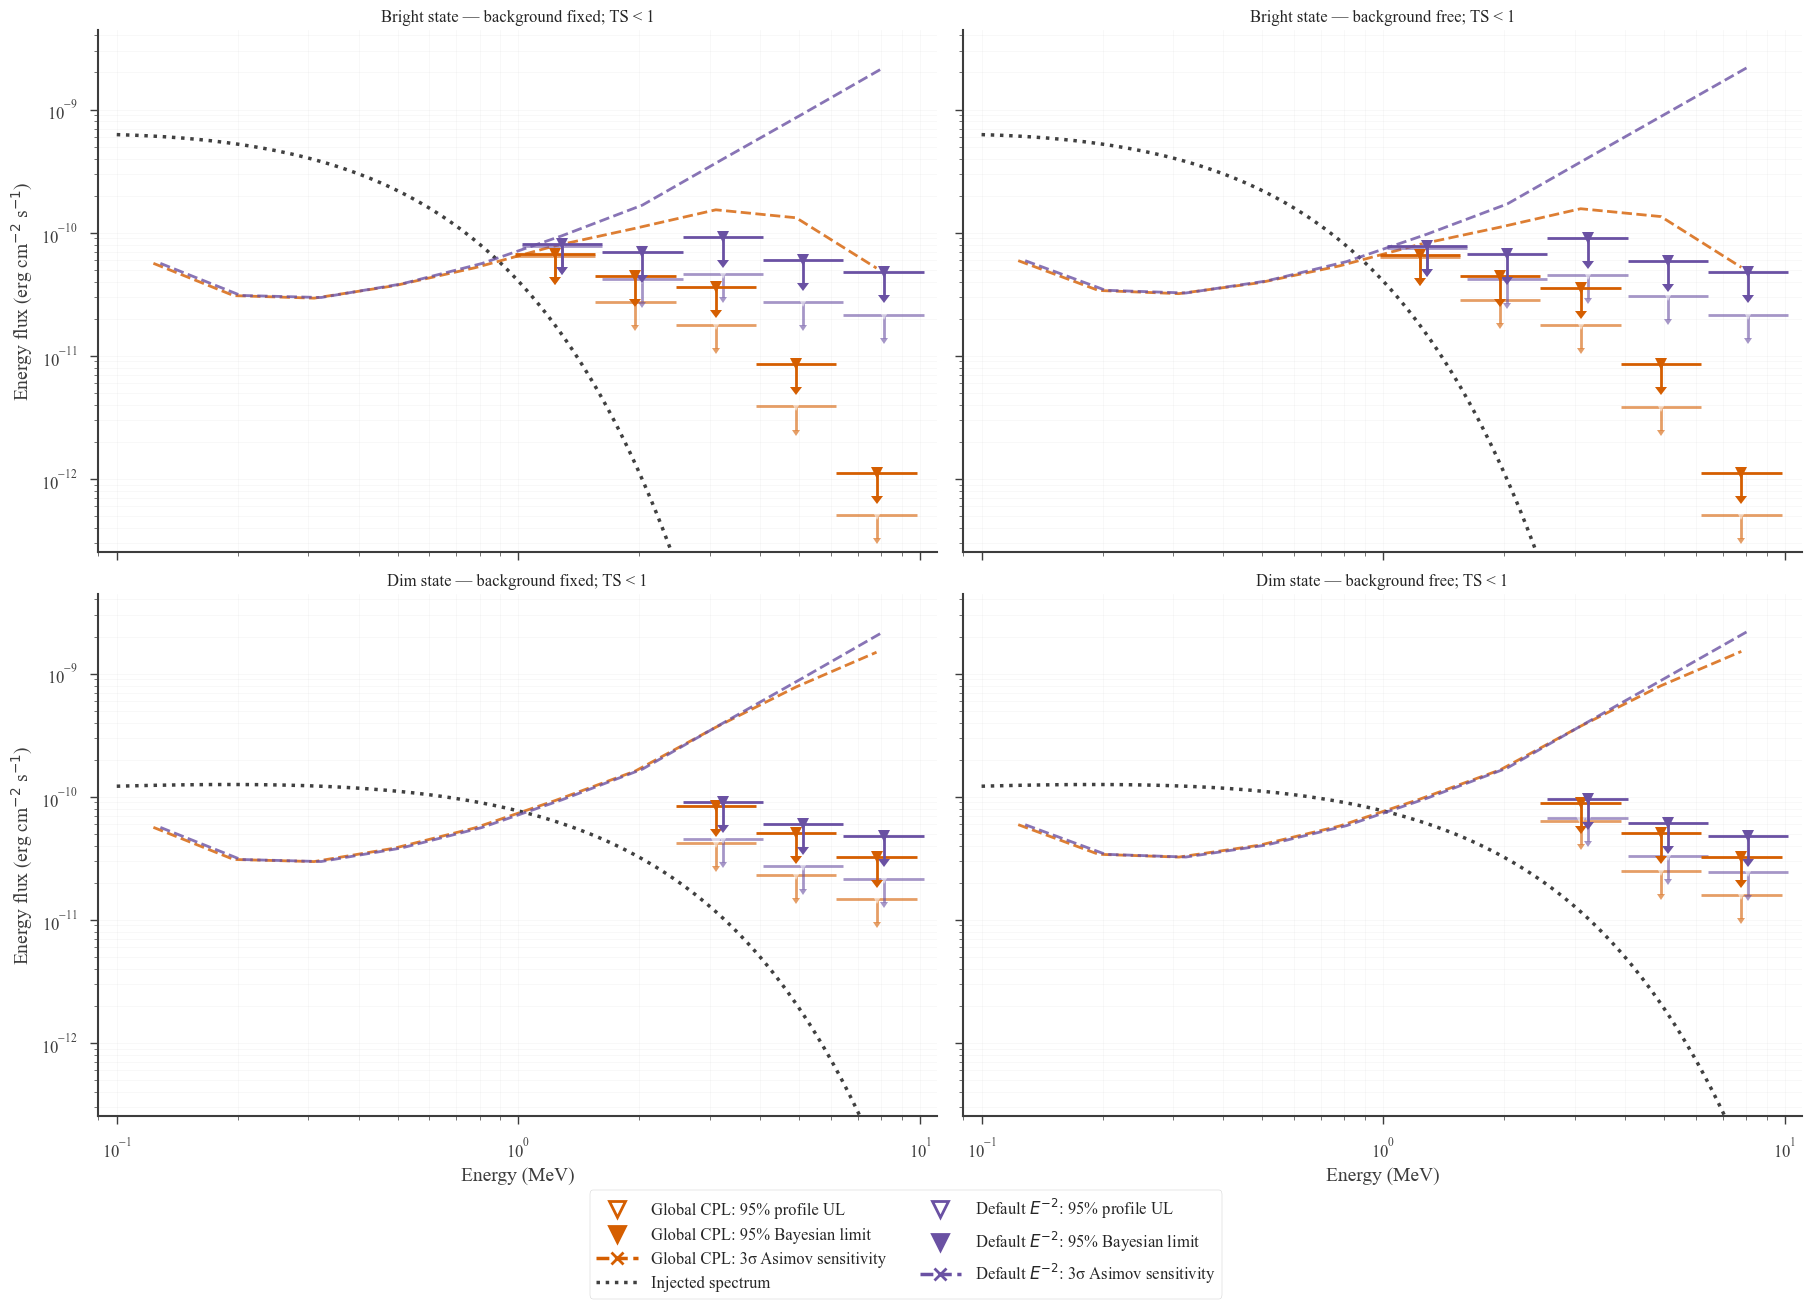

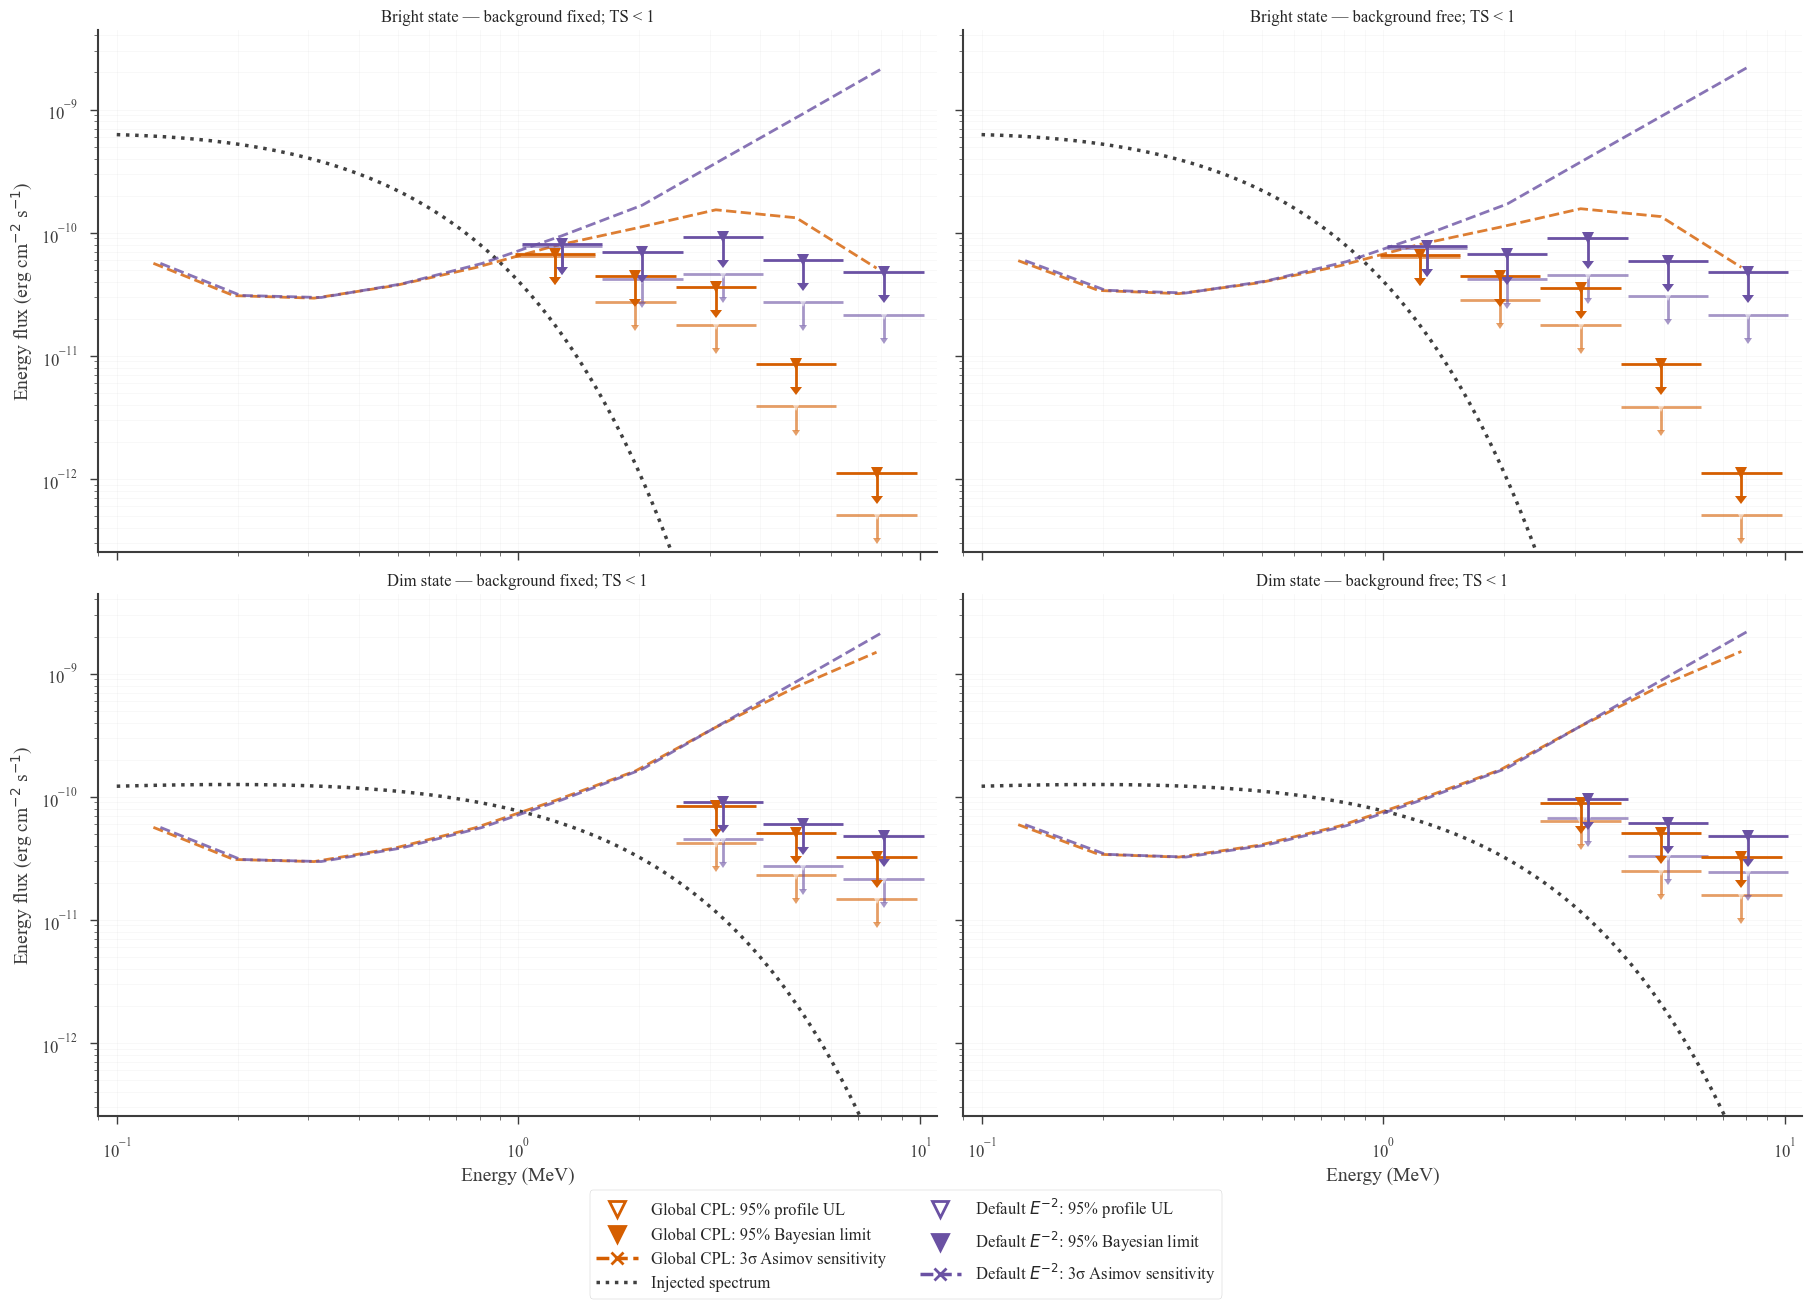

In [32]:
# Fermi Science Tools style 95% posterior limits for TS < 1.
bayes_rows = []
for state, cases in sed_comparisons.items():
    for (shape_name, background_mode), sed in cases.items():
        weak = sed.loc[sed['ts_value'] < 1.0]
        for _, point in weak.iterrows():
            profile = float(point['sed_ul95_erg_cm2_s'])
            bayes = float(point['sed_ul95_bayes_erg_cm2_s'])
            bayes_rows.append({
                'state': state, 'shape': shape_name, 'background': background_mode,
                'bin': int(point['bin_index']),
                'energy_MeV': float(point['e_ref_keV']) * KEV_TO_MEV,
                'TS': float(point['ts_value']),
                'profile_95': profile, 'bayesian_95': bayes,
                'bayes_to_profile': bayes / profile,
            })
bayes_comparison = pd.DataFrame(bayes_rows)
display(bayes_comparison)
fig_bayes = plot_limit_comparison('sed_ul95_bayes_erg_cm2_s',
                                  '95% Bayesian limit', ts_below_one=True)
display(fig_bayes)


### Upper-limit versus Asimov support diagnostic

This table compares only bins plotted as upper limits. The 3σ profile bound and the 3σ Asimov threshold use the same nominal $\Delta$TS = 9, but their ratios need not be one because one uses the observed realization and the other expected background counts. The background-support column exposes an additional implementation difference: the upper-limit likelihood includes all detector cells with the $10^{-12}$ pseudocount, while the Asimov calculation uses only cells with positive raw DC4 background.


In [ ]:
# Read-only diagnostic; reuses the fits and thresholds already computed above.
support_diagnostic_rows = []
for state, cases in sed_comparisons.items():
    for (shape_name, background_mode), sed in cases.items():
        for _, point in sed.loc[sed['plot_role'].eq('upper_limit')].iterrows():
            sensitivity = float(point['sed_asimov_sensitivity3sigma_erg_cm2_s'])
            ul95 = float(point['sed_ul95_erg_cm2_s'])
            ul3sigma = float(point['sed_ul3sigma_erg_cm2_s'])
            support_diagnostic_rows.append({
                'state': state,
                'shape': shape_name,
                'background': background_mode,
                'bin': int(point['bin_index']),
                'energy_MeV': float(point['e_ref_keV']) * KEV_TO_MEV,
                'TS': float(point['ts_value']),
                'raw_supported_source_fraction': float(point['asimov_supported_source_fraction']),
                '95% UL / 3σ sensitivity': ul95 / sensitivity,
                '3σ UL / 3σ sensitivity': ul3sigma / sensitivity,
                '95% UL (erg cm^-2 s^-1)': ul95,
                '3σ UL (erg cm^-2 s^-1)': ul3sigma,
                '3σ sensitivity (erg cm^-2 s^-1)': sensitivity,
            })
support_diagnostics = pd.DataFrame(support_diagnostic_rows)
if support_diagnostics.empty:
    print('No upper-limit bins to compare.')
else:
    display(support_diagnostics.sort_values(['state', 'shape', 'background', 'bin']))
